# Reinforcement Learning and Deep RL: Robots in a Warehouse

Notebook for the *Reinforcement Learning and Deep RL* lab. An LLM (Claude) was used as the
engineering assistant, as the lab asks: it was given this lab's handout - the map, rewards,
stopping rules, hyperparameters and example prompts - and wrote the code below. Every number,
plot and trajectory in this notebook comes from running it end to end; the tests in Tasks 4,
6 and 7 were run before any training result was interpreted.

## Task 1 - Understanding the MDP

A $5 \times 5$ grid, positions $(r, c)$ with rows increasing downwards, obstacles
$\{(0,2), (1,2), (3,2), (4,2)\}$, so the only way between the two rooms is the doorway $(2,2)$.

| Component | Specification |
|---|---|
| State | the robot's cell $(r, c)$ - one of the 21 free cells |
| Actions | 0 Up, 1 Down, 2 Left, 3 Right, 4 Wait |
| Transition rule | move one cell in the chosen direction; a move off the grid or into an obstacle leaves the robot where it is; Wait stays |
| Reward | +10 on reaching $G$; -1 for an attempted obstacle or boundary move; -0.1 for any other action, including Wait (mutually exclusive) |
| Initial state | $S = (2, 0)$ |
| Terminal outcome | reaching $G = (2, 4)$ terminates the task. Separately, a rollout is *truncated* after 40 steps - a data-collection rule, not a terminal state |

(a) Only the robot's current cell $(r, c)$. The step counter is deliberately *not* part of the
state: the 40-step cutoff is not a deadline in the task, which is exactly why a truncated
transition should still bootstrap from the next state.

(b) With the map and goal fixed, everything else about the situation is constant, so the cell
alone determines which moves are valid, what each action returns and where it leads - the
next state and reward depend only on the current cell and action (the Markov property).

(c) Yes. Every (cell, action) pair has exactly one successor and one reward.

(d) Right, Right, Right, Right: $(2,0) \to (2,1) \to (2,2) \to (2,3) \to (2,4)$, 4 steps with
return $3 \times (-0.1) + 10 = 9.7$. It is the only shortest route: the Manhattan distance from
$S$ to $G$ is 4, so a 4-step route can only move right along row 2, which is free.

(e) No. A search algorithm (BFS, A\*) is given the transition model and goal test and plans
the route before acting. Q-learning is never told the model or the route: it acts, observes
rewards, and gradually estimates $Q(s,a)$ from that experience; the route only appears as the
greedy policy with respect to those estimates, after hundreds of episodes rather than a handful
of node expansions.

## Task 2 - Planning the learning agent

1. **Grid and position.** Obstacles are a set of $(r, c)$ tuples; the robot's position is a
   single $(r, c)$ tuple, which is also the state.
2. **`reset` and `step`.** `reset(pos=None)` puts the robot at $S$ (or at a chosen cell, for
   testing) and zeroes the step counter. `step(a)` computes the proposed cell, keeps the old
   cell if the move is invalid, applies exactly one of the three rewards, and returns
   `(next_pos, reward, terminated, truncated, info)`, with `terminated` true only on reaching
   $G$ and `truncated` true only when step 40 ends an unfinished rollout.
3. **Q-table indexing.** A $25 \times 5$ NumPy array; cell $(r, c)$ is row $5r + c$, action
   code is the column. Obstacle rows stay unused.
4. **Epsilon-greedy.** With probability $\varepsilon$ a uniformly random action; otherwise an
   action with the largest Q-value, ties broken at random. $\varepsilon$ falls linearly from 1
   to 0.05 over the first 1,200 of 1,500 episodes.
5. **Terminal flag in the target.** $y = r$ if `terminated`, else $y = r + \gamma \max_{a'} Q(s', a')$.
   The `truncated` flag never enters the target - it only ends the rollout.
6. **When an episode stops.** On termination or truncation, whichever comes first. The update
   for that last step uses the next state returned by `step`, before `reset` is called.
7. **Training vs. evaluation.** Training uses epsilon-greedy and updates the table after every
   step. Evaluation uses $\varepsilon = 0$, a fixed tie-break (lowest action code), and never
   calls the update.

Recorded during training: return per episode, whether the goal was reached, whether it timed
out, the number of invalid moves, $\varepsilon$ and episode length. After training: the greedy
trajectory, its length, invalid moves and outcome.

> **Think about it.** Exploration and learning are disabled in evaluation by construction:
> `greedy_rollout` takes a policy function that only reads the Q-table (or network) and never
> calls `q_update` or the optimizer.

## Task 3 - The LLM implementation

The specification the LLM implemented was the design above plus the handout's example prompt,
which fixes every remaining detail:

> *Implement tabular Q-learning in Python using NumPy for the warehouse environment specified in
> this laboratory. Use a 5x5 grid, the obstacle set {(0,2), (1,2), (3,2), (4,2)}, start (2,0),
> and goal (2,4). Actions are up, down, left, right, and wait. An obstacle or boundary move stays
> in place. Use mutually exclusive rewards: +10 on reaching the goal, -1 for an invalid move, and
> -0.1 for another valid action. Provide separate functions for the environment, epsilon-greedy
> action selection, one Q-learning update, training, and greedy evaluation. Use alpha = 0.2,
> gamma = 0.95, an initially zero Q-table, and seed 7. Train for 1,500 episodes. Decrease epsilon
> linearly from 1 to 0.05 over the first 1,200 episodes. Cut off unfinished episodes after 40
> steps. Return separate termination and truncation flags. Bootstrap at truncation, but not at
> goal termination. Use the next state from before reset in every update. Do not use path search
> or a ready-made RL library. Include a separate test mode in which I can set the robot's
> position, choose one action, and inspect the outcome without training. Report training curves
> and the learned greedy trajectory.*

The code was read through against that specification before anything was run (the mapping is
in the table at the end of Task 4).

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.set_num_threads(1)   # tiny networks: one thread is faster and keeps runs repeatable

ROWS, COLS = 5, 5
OBSTACLES = {(0, 2), (1, 2), (3, 2), (4, 2)}
START, GOAL = (2, 0), (2, 4)
ACTIONS = ["Up", "Down", "Left", "Right", "Wait"]   # action codes 0-4, in this order
DELTAS = [(-1, 0), (1, 0), (0, -1), (0, 1), (0, 0)]
GAMMA = 0.95
MAX_STEPS = 40   # collection cutoff (truncation), not a deadline in the task
SEED = 7

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 100,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlesize": 11,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
})

### The environment

In [2]:
def propose(pos, action):
    """Cell that `action` would move a robot to from `pos`, and whether the move is valid.
    A move off the grid or into an obstacle is invalid and leaves the robot in place."""
    r, c = pos
    dr, dc = DELTAS[action]
    nxt = (r + dr, c + dc)
    if not (0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS) or nxt in OBSTACLES:
        return pos, False
    return nxt, True


class WarehouseEnv:
    def __init__(self, start=START, goal=GOAL, max_steps=MAX_STEPS):
        self.start, self.goal, self.max_steps = start, goal, max_steps

    def reset(self, pos=None):
        self.pos = self.start if pos is None else pos
        self.t = 0
        return self.pos

    def step(self, action):
        self.pos, valid = propose(self.pos, action)
        self.t += 1
        if self.pos == self.goal:            # the three reward cases are mutually exclusive
            reward, terminated = 10.0, True
        elif not valid:
            reward, terminated = -1.0, False
        else:
            reward, terminated = -0.1, False
        truncated = not terminated and self.t >= self.max_steps
        return self.pos, reward, terminated, truncated, {"invalid": int(not valid), "collision": False}


def test_step(pos, action):
    """Test mode: place the robot at `pos`, take one action, and return the outcome. No learning."""
    env = WarehouseEnv()
    env.reset(pos)
    return env.step(action)

### Q-learning: action selection, the update, training and greedy evaluation

In [3]:
def state_index(pos):
    return 5 * pos[0] + pos[1]          # row of the 25 x 5 Q-table; obstacle rows stay unused


def linear_epsilon(i, decay_over, start=1.0, end=0.05):
    return max(end, start - (start - end) * i / decay_over)


def epsilon_greedy(Q, s, epsilon, rng):
    """Training-time action choice: random with probability epsilon, otherwise a greedy
    action with ties broken at random."""
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))


def greedy_action(Q, s):
    return int(np.argmax(Q[s]))         # evaluation: fixed tie-break, lowest action code


def td_target(r, next_max, terminated, gamma=GAMMA):
    return r if terminated else r + gamma * next_max


def q_update(Q, s, a, r, s_next, terminated, alpha=0.2, gamma=GAMMA):
    """One tabular Q-learning update of Q[s, a]. Only true termination drops the
    continuation term; a truncated transition is passed with terminated=False."""
    y = td_target(r, Q[s_next].max(), terminated, gamma)
    Q[s, a] += alpha * (y - Q[s, a])
    return y


def train_q_learning(episodes=1500, alpha=0.2, gamma=GAMMA, decay_episodes=1200,
                     seed=SEED, explore=True):
    rng = np.random.default_rng(seed)
    env, Q = WarehouseEnv(), np.zeros((ROWS * COLS, len(ACTIONS)))
    log = {k: [] for k in ("return", "success", "timeout", "invalid", "epsilon", "length")}
    for ep in range(episodes):
        eps = linear_epsilon(ep, decay_episodes) if explore else 0.0
        pos, ret, invalid = env.reset(), 0.0, 0
        while True:
            s = state_index(pos)
            a = epsilon_greedy(Q, s, eps, rng)
            pos, r, terminated, truncated, info = env.step(a)
            q_update(Q, s, a, r, state_index(pos), terminated, alpha, gamma)   # pos = next state, before any reset
            ret += r
            invalid += info["invalid"]
            if terminated or truncated:
                break
        for k, v in zip(log, (ret, terminated, truncated, invalid, eps, env.t)):
            log[k].append(v)
    return Q, {k: np.array(v) for k, v in log.items()}


def greedy_rollout(env, choose, start=None):
    """Run one episode with a fixed policy `choose(obs) -> action`; no exploration, no updates."""
    obs = env.reset(start)
    path, actions, invalid, ret = [obs], [], 0, 0.0
    while True:
        a = choose(obs)
        obs, r, terminated, truncated, info = env.step(a)
        path.append(obs)
        actions.append(a)
        invalid += info["invalid"]
        ret += r
        if terminated or truncated:
            outcome = ("collision" if info["collision"] else "success") if terminated else "timeout"
            return {"outcome": outcome, "steps": len(actions), "invalid": invalid,
                    "return": round(ret, 3), "path": path, "actions": actions}


def draw_path(path):
    grid = [["#" if (r, c) in OBSTACLES else "." for c in range(COLS)] for r in range(ROWS)]
    for t, (r, c) in enumerate(path):
        grid[r][c] = str(t % 10)
    return "\n".join(" ".join(row) for row in grid)

## Task 4 - Testing the environment and the update, before any training

Each case sets the starting cell explicitly through the test mode (`test_step`), so no
learning or random policy is involved.

In [4]:
env_cases = [   # (position, action, expected next position, expected reward, expected termination)
    ((0, 0), "Up",    (0, 0), -1.0, False),
    ((1, 1), "Right", (1, 1), -1.0, False),
    ((2, 1), "Right", (2, 2), -0.1, False),
    ((2, 1), "Wait",  (2, 1), -0.1, False),
    ((2, 3), "Right", (2, 4), 10.0, True),
]
print(f"{'position':<10}{'action':<8}{'next':<10}{'reward':>7}  terminated  truncated")
for pos, name, exp_pos, exp_r, exp_term in env_cases:
    nxt, r, term, trunc, _ = test_step(pos, ACTIONS.index(name))
    print(f"{str(pos):<10}{name:<8}{str(nxt):<10}{r:>7}  {str(term):<10}  {trunc}")
    assert (nxt, r, term, trunc) == (exp_pos, exp_r, exp_term, False)
print("all five single-step cases match the expected results\n")

env = WarehouseEnv()
env.reset()
flags = [env.step(ACTIONS.index("Wait"))[2:4] for _ in range(MAX_STEPS)]
assert all(f == (False, False) for f in flags[:-1]) and flags[-1] == (False, True)
print(f"waiting from S: steps 1-{MAX_STEPS - 1} neither terminate nor truncate; "
      f"step {MAX_STEPS} reports truncated=True, terminated=False")

env.reset((2, 3))
for _ in range(MAX_STEPS - 1):
    env.step(ACTIONS.index("Wait"))
_, r, term, trunc, _ = env.step(ACTIONS.index("Right"))
assert (r, term, trunc) == (10.0, True, False)
print(f"reaching G on exactly step {MAX_STEPS} counts as termination, not truncation")

position  action  next       reward  terminated  truncated
(0, 0)    Up      (0, 0)       -1.0  False       False
(1, 1)    Right   (1, 1)       -1.0  False       False
(2, 1)    Right   (2, 2)       -0.1  False       False
(2, 1)    Wait    (2, 1)       -0.1  False       False
(2, 3)    Right   (2, 4)       10.0  True        False
all five single-step cases match the expected results

waiting from S: steps 1-39 neither terminate nor truncate; step 40 reports truncated=True, terminated=False
reaching G on exactly step 40 counts as termination, not truncation


**One synthetic Q-learning update.** With $Q(s,a) = 0.4$, $r = 1$,
$\max_{a'} Q(s',a') = 2$, $\alpha = 0.2$, $\gamma = 0.95$, by hand:

- non-terminal: $y = 1 + 0.95 \times 2 = 2.9$, new $Q(s,a) = 0.4 + 0.2\,(2.9 - 0.4) = 0.9$;
- true termination with $r = 5$: $y = 5$, new $Q(s,a) = 0.4 + 0.2\,(5 - 0.4) = 1.32$;
- the non-terminal example again, but truncated: $y = 2.9$ and $Q(s,a) = 0.9$, the same as the
  non-terminal case, because truncation does not end the task.

This is a synthetic test of `q_update` alone, using a scratch table, not an environment
transition.

In [5]:
def synthetic_update(r, terminated):
    Q = np.zeros((2, len(ACTIONS)))
    Q[0, 0] = 0.4                      # Q(s, a) = 0.4
    Q[1, 3] = 2.0                      # max_a' Q(s', a') = 2
    y = q_update(Q, 0, 0, r, 1, terminated, alpha=0.2, gamma=0.95)
    return y, Q[0, 0]

cases = [   # (label, r, terminated flag passed to the update, hand-computed target, hand-computed new Q)
    ("non-terminal",     1.0, False, 1 + 0.95 * 2, 0.4 + 0.2 * (2.9 - 0.4)),
    ("true termination", 5.0, True,  5.0,          0.4 + 0.2 * (5.0 - 0.4)),
    ("truncated",        1.0, False, 1 + 0.95 * 2, 0.4 + 0.2 * (2.9 - 0.4)),
]
for label, r, term, exp_y, exp_q in cases:
    y, q = synthetic_update(r, term)
    print(f"{label:<17} target = {y:.4f} (by hand {exp_y:.4f})   new Q(s,a) = {q:.4f} (by hand {exp_q:.4f})")
    assert np.isclose(y, exp_y) and np.isclose(q, exp_q)

non-terminal      target = 2.9000 (by hand 2.9000)   new Q(s,a) = 0.9000 (by hand 0.9000)
true termination  target = 5.0000 (by hand 5.0000)   new Q(s,a) = 1.3200 (by hand 1.3200)
truncated         target = 2.9000 (by hand 2.9000)   new Q(s,a) = 0.9000 (by hand 0.9000)


All three agree with the hand calculation. **Only true termination ignores the
next-state value**; truncation keeps $\gamma \max_{a'} Q(s', a')$ because the task itself would
have continued from $s'$.

| Concept | Function or line in the program |
|---|---|
| State and action representation | `state_index` ($5r + c$), `ACTIONS` / `DELTAS` (codes 0-4) |
| Reward and termination | `WarehouseEnv.step` (the three-way reward, `terminated`, `truncated`) and `propose` (validity) |
| Epsilon-greedy action choice | `epsilon_greedy` (training), `greedy_action` (evaluation), `linear_epsilon` |
| TD target and Q-table update | `td_target` and `q_update` |
| Training and greedy evaluation | `train_q_learning`, `greedy_rollout` |

> **Think about it.** These tests check the problem (environment) and the algorithm (update)
> separately: the five transitions and the cutoff would catch an environment bug even with a
> perfect update, and the synthetic update would catch a wrong target even in a perfect
> environment.

## Task 5 - Training, evaluation and exploration

Training curves use a **50-episode moving average** (the faint line is the raw per-episode
return).

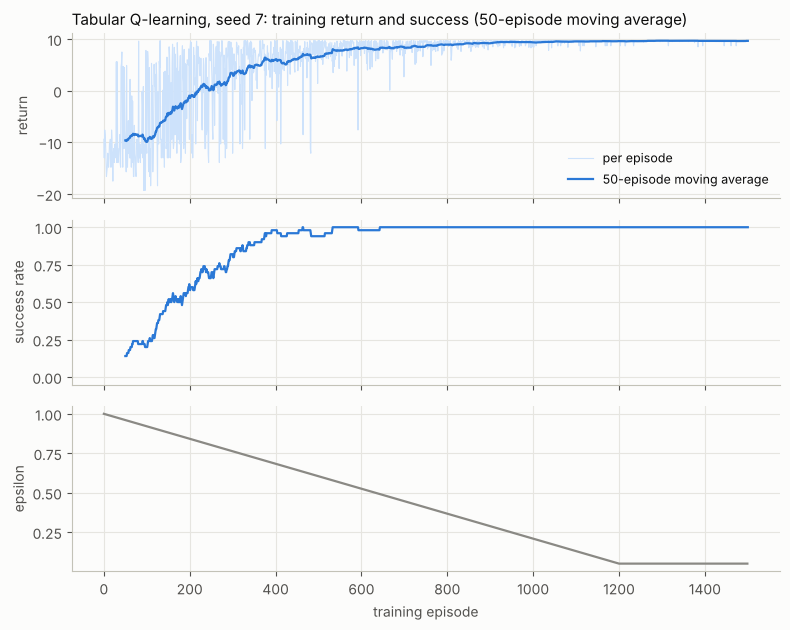

first successful episode: 29; total environment steps used: 18687
last 100 episodes: success 1.00, mean return 9.65, mean length 4.2, epsilon 0.05


In [6]:
Q, qlog = train_q_learning()

WINDOW = 50
def moving_average(x, w=WINDOW):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

def plot_training(log, title, xlabel="training episode"):
    fig, axes = plt.subplots(3, 1, figsize=(8, 6.4), sharex=True)
    n = len(log["return"])
    x_ma = np.arange(WINDOW, n + 1)
    axes[0].plot(log["return"], color="#cde2fb", linewidth=0.8, label="per episode")
    axes[0].plot(x_ma, moving_average(log["return"]), color=BLUE, label=f"{WINDOW}-episode moving average")
    axes[0].set_ylabel("return")
    axes[0].legend(frameon=False, loc="lower right", fontsize=9)
    axes[1].plot(x_ma, moving_average(log["success"]), color=BLUE)
    axes[1].set_ylabel("success rate")
    axes[1].set_ylim(-0.05, 1.05)
    axes[2].plot(log["epsilon"], color=GREY)
    axes[2].set_ylabel("epsilon")
    axes[2].set_xlabel(xlabel)
    axes[0].set_title(title, loc="left")
    fig.tight_layout()
    plt.show()

plot_training(qlog, f"Tabular Q-learning, seed {SEED}: training return and success ({WINDOW}-episode moving average)")

first = int(np.argmax(qlog["success"]))
print(f"first successful episode: {first}; total environment steps used: {qlog['length'].sum()}")
print(f"last 100 episodes: success {qlog['success'][-100:].mean():.2f}, "
      f"mean return {qlog['return'][-100:].mean():.2f}, mean length {qlog['length'][-100:].mean():.1f}, "
      f"epsilon {qlog['epsilon'][-1]:.2f}")

### Greedy evaluation from the default start ($\varepsilon = 0$, no updates)

In [7]:
q_policy = lambda pos: greedy_action(Q, state_index(pos))
q_eval = greedy_rollout(WarehouseEnv(), q_policy)
print("greedy actions:", [ACTIONS[a] for a in q_eval["actions"]])
print("positions     :", q_eval["path"])
print(f"outcome {q_eval['outcome']}, {q_eval['steps']} steps, {q_eval['invalid']} invalid moves, return {q_eval['return']}")
print("\nnumbers mark the time step at which the robot occupies each cell (# = obstacle):")
print(draw_path(q_eval["path"]))

greedy actions: ['Right', 'Right', 'Right', 'Right']
positions     : [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
outcome success, 4 steps, 0 invalid moves, return 9.7

numbers mark the time step at which the robot occupies each cell (# = obstacle):
. . # . .
. . # . .
0 1 2 3 4
. . # . .
. . # . .


The greedy policy takes the 4-step route from Task 1 - the shortest one - with no
invalid moves.

### Comparison with a uniformly random policy (100 runs, same map, start, rewards and cutoff)

In [8]:
rand_rng = np.random.default_rng(SEED)
random_runs = [greedy_rollout(WarehouseEnv(), lambda pos: int(rand_rng.integers(len(ACTIONS))))
               for _ in range(100)]
succ_steps = [r["steps"] for r in random_runs if r["outcome"] == "success"]
rand_success = np.mean([r["outcome"] == "success" for r in random_runs])
rand_timeout = np.mean([r["outcome"] == "timeout" for r in random_runs])
rand_invalid = np.mean([r["invalid"] for r in random_runs])

print(f"{'Measure':<30}{'Random policy (100 runs)':>26}{'Greedy Q-policy':>18}")
yes_no = lambda flag: "yes" if flag else "no"
print(f"{'Goal reached':<30}{f'{rand_success:.2f} of runs':>26}{yes_no(q_eval['outcome'] == 'success'):>18}")
print(f"{'Steps to goal, if successful':<30}{f'mean {np.mean(succ_steps):.1f} over {len(succ_steps)} runs':>26}{q_eval['steps']:>18}")
print(f"{'Timeouts':<30}{f'{rand_timeout:.2f} of runs':>26}{yes_no(q_eval['outcome'] == 'timeout'):>18}")
print(f"{'Invalid moves':<30}{f'mean {rand_invalid:.1f} per run':>26}{q_eval['invalid']:>18}")

Measure                         Random policy (100 runs)   Greedy Q-policy
Goal reached                                0.18 of runs               yes
Steps to goal, if successful      mean 26.9 over 18 runs                 4
Timeouts                                    0.82 of runs                no
Invalid moves                           mean 9.9 per run                 0


**(a) Why does the training curve stay noisy after a good route is learned?** The
curve measures the *exploring* policy, not the greedy one. Even at the floor $\varepsilon = 0.05$,
each step has a $0.05 \times 4/5 = 4\%$ chance of a non-greedy action, so roughly one episode in
seven still contains a detour, and a random step into a wall costs -1 rather than -0.1. Each
point is also a single episode's return, so the average over 50 episodes still moves around.

**(b) Does a high training return imply a good greedy policy?** No. Training return is earned
by a different policy (epsilon-greedy) while the table is still changing; a run can collect high
returns from lucky exploratory episodes, and a single wrong greedy action in a state the
exploring policy rarely visits can still make the greedy rollout loop until the cutoff. The
greedy rollout above, not the curve, is the evidence for the learned policy.

**(c) Learning rate $\alpha$ vs. exploration probability $\varepsilon$.** $\alpha$ controls *how
much* one update moves $Q(s,a)$ toward its target (the step size of learning from data);
$\varepsilon$ controls *which actions are tried* and therefore which data is collected at all.
$\alpha$ acts inside `q_update`, $\varepsilon$ inside `epsilon_greedy`; neither is used in greedy
evaluation.

### Optional investigation - no exploration

A fresh table trained with $\varepsilon = 0$ throughout (greedy with random tie-breaking), all
other settings fixed, for seed 7 and a second seed:

In [9]:
print(f"{'run':<26}{'first success':>14}{'training success':>18}{'greedy outcome':>16}{'steps':>7}")
for seed in (SEED, 8):
    for explore in (True, False):
        Qx, logx = train_q_learning(seed=seed, explore=explore)
        ev = greedy_rollout(WarehouseEnv(), lambda pos: greedy_action(Qx, state_index(pos)))
        label = f"seed {seed}, " + ("epsilon-greedy" if explore else "no exploration")
        print(f"{label:<26}{int(np.argmax(logx['success'])):>14}{logx['success'].mean():>18.3f}"
              f"{ev['outcome']:>16}{ev['steps']:>7}")

Q0, _ = train_q_learning(explore=False)
visited = sum(np.any(Q0[state_index((r, c))] != 0) for r in range(ROWS) for c in range(COLS))
print(f"\nno-exploration Q-table, seed {SEED}: {visited} of 21 free cells have at least one updated entry")

run                        first success  training success  greedy outcome  steps


seed 7, epsilon-greedy                29             0.889         success      4


seed 7, no exploration                 2             0.998         success      4


seed 8, epsilon-greedy                 1             0.901         success      4


seed 8, no exploration                 2             0.998         success      4



no-exploration Q-table, seed 7: 15 of 21 free cells have at least one updated entry


Training without exploration also finds the 4-step route here, for both seeds. The
reason is the zero-initialised table combined with step costs: every action the robot tries gets
a *negative* value (-0.1 or -1), while untried actions keep the value 0 and therefore win the
greedy comparison next time. The table behaves "optimistically" and pushes the robot to try new
actions, and random tie-breaking among the zeros spreads those tries around - so exploration
happens anyway, just not through $\varepsilon$. This would not carry over to an environment with
positive step rewards, or to a table initialised with large negative values. Even so, the
greedy-only table updated entries for just 15 of the 21 free cells, against far wider coverage
with $\varepsilon$ starting at 1.

Its *training* success (0.998) is also higher than epsilon-greedy's (0.889) - not because it
learned better, but because the training curve of the exploring run includes its random actions.
That is the point of question (b) from the other side: training numbers describe the behaviour
policy, and only the greedy rollout describes what was learned.

## Task 6 - Replacing the table with a neural network (DQN)

**What stays the same:** the environment, rewards, $\gamma = 0.95$, termination vs. truncation
handling (bootstrap at truncation, reward-only target at termination), epsilon-greedy
exploration during training, and greedy evaluation with learning switched off.

**What changes:** $Q(s, \cdot)$ now comes from a network $25 \to 64 \to 64 \to 5$ (ReLU hidden
units, five linear outputs - Q-values, not probabilities) applied to a one-hot encoding of the
cell (a 1 at index $5r + c$). Instead of updating one table entry per step, transitions go into a
replay buffer and the network takes gradient steps on random minibatches. Targets are computed
by a separate target network, and $\varepsilon$ decays over environment steps (80% of 12,000)
instead of episodes.

Specification given to the LLM (the handout's example prompt):

> *Extend my validated single-robot program to use DQN in PyTorch. Keep the environment,
> rewards, start, goal, and discount unchanged. Use the specified one-hot input and two 64-unit
> ReLU hidden layers. Output five Q-values without softmax. Use epsilon-greedy action selection,
> a replay buffer, and a target network. Use a replay capacity of 20,000 transitions and random
> batches of 64. Initialize the target network from the online network. Collect 500 steps before
> learning, perform one optimizer update every four environment steps, and copy the online
> weights to the target every 250 optimizer updates. Use Adam with learning rate 0.001 and mean
> squared TD error. Compute detached targets with torch.no_grad(). Use a reward-only target for
> termination and bootstrap at truncation. Train for 12,000 environment steps with seed 7.
> Decrease epsilon linearly from 1 to 0.05 over the first 80 percent of training. Keep training
> and greedy evaluation separate. Explain where the recorded action is selected when computing
> the loss.*

**Where the recorded action is selected:** in `dqn_loss`, `online(s).gather(1, a.unsqueeze(1))`
picks, for each transition in the batch, the output column of the action that was actually
taken when the transition was recorded. Only that entry is compared with the target, so only
it receives gradient from that transition; the other four outputs are untouched by it.

In [10]:
def one_hot(pos):
    x = torch.zeros(ROWS * COLS)
    x[state_index(pos)] = 1.0
    return x


def make_qnet(n_inputs, n_actions):
    # outputs are Q-values, one per action: linear output layer, no softmax
    return nn.Sequential(nn.Linear(n_inputs, 64), nn.ReLU(),
                         nn.Linear(64, 64), nn.ReLU(),
                         nn.Linear(64, n_actions))


class ReplayBuffer:
    """Fixed-capacity ring buffer of (s, a, r, s', terminated); the oldest entries are overwritten."""
    def __init__(self, capacity, state_dim, rng):
        self.s = torch.zeros(capacity, state_dim)
        self.a = torch.zeros(capacity, dtype=torch.long)
        self.r = torch.zeros(capacity)
        self.s2 = torch.zeros(capacity, state_dim)
        self.term = torch.zeros(capacity)
        self.capacity, self.size, self.next, self.rng = capacity, 0, 0, rng

    def add(self, s, a, r, s2, terminated):
        i = self.next
        self.s[i], self.a[i], self.r[i], self.s2[i], self.term[i] = s, a, r, s2, float(terminated)
        self.next = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = torch.as_tensor(self.rng.choice(self.size, batch_size, replace=False))
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.term[idx]


def dqn_loss(online, target, batch, gamma=GAMMA):
    s, a, r, s2, term = batch
    # Q_theta(s, a) for the action that was actually recorded in each transition
    q_sa = online(s).gather(1, a.unsqueeze(1)).squeeze(1)
    with torch.no_grad():        # targets come from the target network and carry no gradient
        y = r + gamma * (1.0 - term) * target(s2).max(dim=1).values
    return nn.functional.mse_loss(q_sa, y), q_sa, y


def train_dqn(env, encode, n_inputs, n_actions, total_steps, seed=SEED, capacity=20_000,
              batch_size=64, warmup=500, train_every=4, sync_every=250, lr=1e-3,
              eps_fraction=0.8):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    online, target = make_qnet(n_inputs, n_actions), make_qnet(n_inputs, n_actions)
    target.load_state_dict(online.state_dict())
    optimiser = torch.optim.Adam(online.parameters(), lr=lr)
    buffer = ReplayBuffer(capacity, n_inputs, rng)
    log = {k: [] for k in ("return", "success", "collision", "timeout", "invalid", "epsilon", "length")}
    updates = syncs = 0

    obs, ret, invalid = env.reset(), 0.0, 0
    for step in range(total_steps):
        eps = linear_epsilon(step, eps_fraction * total_steps)
        x = encode(obs)
        if rng.random() < eps:
            a = int(rng.integers(n_actions))
        else:
            with torch.no_grad():
                a = int(online(x).argmax())
        obs_next, r, terminated, truncated, info = env.step(a)
        buffer.add(x, a, r, encode(obs_next), terminated)   # next state from before any reset
        ret += r
        invalid += info["invalid"]
        if terminated or truncated:
            collided = bool(info["collision"])
            for k, v in zip(log, (ret, terminated and not collided, collided, truncated,
                                  invalid, eps, env.t)):
                log[k].append(v)
            obs, ret, invalid = env.reset(), 0.0, 0
        else:
            obs = obs_next

        if buffer.size >= warmup and (step + 1) % train_every == 0:
            loss, _, _ = dqn_loss(online, target, buffer.sample(batch_size))
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
            updates += 1
            if updates % sync_every == 0:
                target.load_state_dict(online.state_dict())
                syncs += 1
    log = {k: np.array(v) for k, v in log.items()}
    log["updates"], log["syncs"] = updates, syncs
    return online, log


def net_policy(net, encode):
    def choose(obs):
        with torch.no_grad():
            return int(net(encode(obs)).argmax())   # argmax: fixed tie-break, first maximum
    return choose

### Testing the loss before training

A batch of three transitions whose targets are known: the target network's last layer is
overwritten so that $\max_{a'} Q_{\theta^-}(s', a') = 2$ in every state. By hand, with
$\gamma = 0.95$: non-terminal $r = 1 \Rightarrow y = 2.9$; terminal $r = 5 \Rightarrow y = 5$
(next-state value ignored); truncated $r = 1 \Rightarrow y = 2.9$.

In [11]:
torch.manual_seed(0)
online_t, target_t = make_qnet(25, 5), make_qnet(25, 5)
with torch.no_grad():                       # make every next-state value of the target network known
    target_t[-1].weight.zero_()
    target_t[-1].bias.copy_(torch.tensor([2.0, 0.0, -1.0, 0.5, 1.0]))   # max_a' = 2 in every state

s  = torch.stack([one_hot((2, 1)), one_hot((2, 3)), one_hot((0, 0))])
a  = torch.tensor([3, 3, 0])
r  = torch.tensor([1.0, 5.0, 1.0])
s2 = torch.stack([one_hot((2, 2)), one_hot((2, 4)), one_hot((0, 0))])
term = torch.tensor([0.0, 1.0, 0.0])        # row 3 is a truncated transition: terminated stays 0

loss, q_sa, y = dqn_loss(online_t, target_t, (s, a, r, s2, term))
print("targets             :", [round(v, 4) for v in y.tolist()], " by hand: [2.9, 5.0, 2.9]")
assert torch.allclose(y, torch.tensor([2.9, 5.0, 2.9]))

all_q = online_t(s).detach()
print("Q_theta(s, .) rows  :", [[round(v, 3) for v in row] for row in all_q.tolist()])
print("recorded actions    :", a.tolist(), " -> Q_theta(s, a):", [round(v, 3) for v in q_sa.tolist()])
assert torch.equal(q_sa.detach(), all_q[torch.arange(3), a])
by_hand = ((all_q[torch.arange(3), a] - torch.tensor([2.9, 5.0, 2.9])) ** 2).mean()
print(f"loss {loss.item():.5f}, recomputed by hand {by_hand.item():.5f}")
assert torch.isclose(loss, by_hand)

loss.backward()
assert all(p.grad is None for p in target_t.parameters())
assert all(p.grad is not None for p in online_t.parameters())
assert not y.requires_grad
print("gradients reach the online network only; the targets are constants")

targets             : [2.9, 5.0, 2.9]  by hand: [2.9, 5.0, 2.9]
Q_theta(s, .) rows  : [[-0.02, 0.063, 0.062, 0.126, -0.029], [0.013, 0.036, 0.071, 0.122, -0.048], [-0.03, 0.049, 0.063, 0.098, -0.046]]
recorded actions    : [3, 3, 0]  -> Q_theta(s, a): [0.126, 0.122, -0.03]
loss 13.36031, recomputed by hand 13.36031
gradients reach the online network only; the targets are constants


The targets match, the loss uses $Q_\theta(s, a)$ of the *recorded* action
(recomputing it by hand from the full output rows gives the same number), and after
`backward()` the target network has no gradients at all.

### Training and greedy evaluation

1357 training episodes, 2876 optimizer updates, 11 target-network syncs


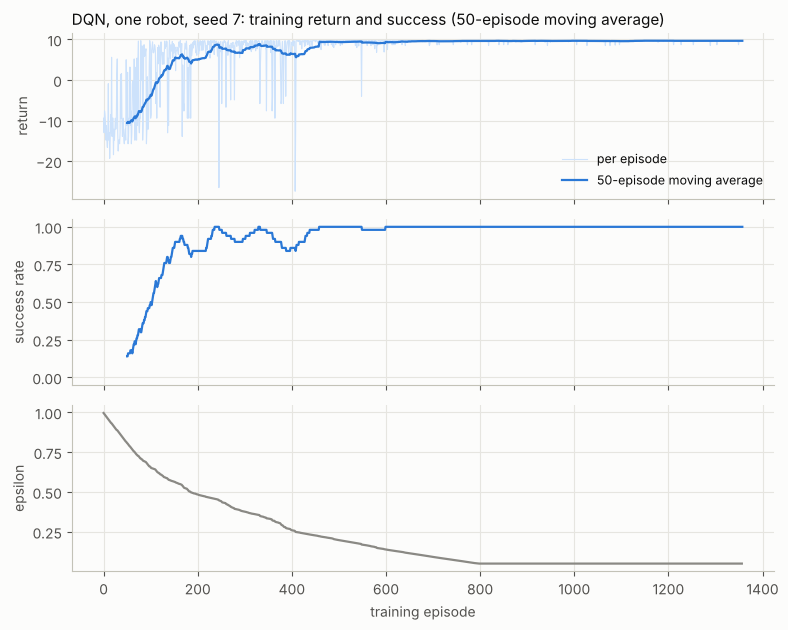

last 100 episodes: success 1.00, mean return 9.65, mean length 4.2

greedy actions: ['Right', 'Right', 'Right', 'Right']
positions     : [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4)]
outcome success, 4 steps, 0 invalid moves
same route as the Q-table: True


In [12]:
dqn, dqn_log = train_dqn(WarehouseEnv(), one_hot, 25, 5, total_steps=12_000)
print(f"{len(dqn_log['return'])} training episodes, {dqn_log['updates']} optimizer updates, "
      f"{dqn_log['syncs']} target-network syncs")
plot_training(dqn_log, f"DQN, one robot, seed {SEED}: training return and success ({WINDOW}-episode moving average)")
print(f"last 100 episodes: success {dqn_log['success'][-100:].mean():.2f}, "
      f"mean return {dqn_log['return'][-100:].mean():.2f}, mean length {dqn_log['length'][-100:].mean():.1f}")

dqn_eval = greedy_rollout(WarehouseEnv(), net_policy(dqn, one_hot))
print("\ngreedy actions:", [ACTIONS[a] for a in dqn_eval["actions"]])
print("positions     :", dqn_eval["path"])
print(f"outcome {dqn_eval['outcome']}, {dqn_eval['steps']} steps, {dqn_eval['invalid']} invalid moves")
print("same route as the Q-table:", dqn_eval["path"] == q_eval["path"])

DQN's greedy route is the same 4-step route the Q-table found, with no invalid
moves. The counters confirm the replay/target schedule: updates start once 500 transitions are
stored and happen every 4 steps, giving $(12000 - 500)/4 + 1 = 2876$ optimizer updates and
$\lfloor 2876 / 250 \rfloor = 11$ target-network copies.

| Concept | Where it is in the code |
|---|---|
| Replay buffer | `ReplayBuffer` (ring buffer of 20,000 transitions); `buffer.add(...)` after every step in `train_dqn` |
| Batch sampling | `ReplayBuffer.sample` - 64 indices drawn uniformly without replacement |
| TD target | the `y = r + gamma * (1 - term) * target(s2).max(...)` line in `dqn_loss`, inside `torch.no_grad()` |
| Optimizer step | `optimiser.zero_grad(); loss.backward(); optimiser.step()` in `train_dqn`, once 500 transitions are stored and every 4th step |
| Target-network sync | `target.load_state_dict(online.state_dict())` every 250 optimizer updates (and once at initialisation) |

> **Think about it.** The Q-table holds 105 numbers (21 free cells x 5 actions); the network
> represents the same values with 6,149 parameters. On this grid that buys nothing - the point is
> to see the same TD target and greedy policy expressed through a function approximator. The two
> runs also used different budgets (1,500 episodes, which came to 18,687 environment steps, vs.
> 12,000 steps), so they say nothing about which method is more sample-efficient.

## Task 7 - Two robots and collision avoidance

| Robot | Start | Goal |
|---|---|---|
| A | (2, 0) | (2, 4) |
| B | (2, 4) | (2, 0) |

### First, the controller design

One controller observes both robots and chooses both moves: state $(p_A, p_B)$, joint action
$(a_A, a_B)$.

(a) **Why observing only A is insufficient.** Whether A should step into the doorway depends on
where B is - the same A position calls for "go" or "wait" depending on B - and collisions and
rewards depend on both positions. A state without $p_B$ is not Markov, and the controller also
has to choose B's move, which needs B's position.

(b) **Representation.** The ordered pair $(p_A, p_B)$, encoded as two concatenated length-25
one-hot vectors (A first): 50 inputs.

(c) **Joint actions.** $5 \times 5 = 25$, encoded as $j = 5a_A + a_B$ and decoded with
`divmod(j, 5)`. The network has 25 linear outputs.

(d) **One collision-free route, by hand.** Each robot starts on the other's goal and the
doorway row is a single lane, so one robot has to get out of the way. Here B goes first and A
steps up into the left room:

| $t$ | A | B | joint action |
|---|---|---|---|
| 0 | (2,0) | (2,4) | |
| 1 | (1,0) | (2,3) | (Up, Left) |
| 2 | (1,1) | (2,2) | (Right, Left) |
| 3 | (1,1) | (2,1) | (Wait, Left) |
| 4 | (2,1) | (2,0) - delivered | (Down, Left): A follows B into (2,1) as B leaves it |
| 5 | (2,2) | (2,0) | (Right, -) |
| 6 | (2,3) | (2,0) | (Right, -) |
| 7 | (2,4) - delivered | (2,0) | (Right, -) |

(e) **Where a robot must wait or move aside.** Row 2 between the rooms ($(2,1)$, $(2,2)$,
$(2,3)$) is one lane, so the robots cannot pass each other there. One robot has to leave row 2
for a cell such as $(1,0)$, $(1,1)$, $(3,0)$, $(3,1)$ on the left or $(1,3)$, $(1,4)$, $(3,3)$,
$(3,4)$ on the right, and wait there until the other has gone past.

### Simultaneous movement, collisions and the team reward

Both proposed moves are computed from the same old state; an obstacle or boundary move becomes a
stay, and a robot already at its goal stays whatever it is asked to do. A **same-cell
collision** is two equal proposed cells (this includes entering a waiting robot's cell); a
**swap collision** is the robots exchanging their old cells. Following a robot into the cell it
is vacating is allowed when the final cells differ and there is no swap. On collision the old
positions are kept and the episode terminates with $r = -10$; otherwise
$r = -0.1 - b + 5k + 5I$, with $b$ invalid moves by undelivered robots, $k$ robots newly reaching
their own goals, and $I = 1$ once both are delivered (which also terminates). Unfinished rollouts
are truncated after 40 joint steps.

In [13]:
A_START, B_START = (2, 0), (2, 4)
A_GOAL, B_GOAL = (2, 4), (2, 0)


def encode_joint(positions):
    return torch.cat([one_hot(positions[0]), one_hot(positions[1])])   # 50 inputs


def joint_action(a_A, a_B):
    return 5 * a_A + a_B


class TwoRobotEnv:
    def __init__(self, starts=(A_START, B_START), goals=(A_GOAL, B_GOAL), max_steps=MAX_STEPS):
        self.starts, self.goals, self.max_steps = starts, goals, max_steps

    def reset(self, positions=None):
        self.pos = tuple(self.starts if positions is None else positions)
        self.t = 0
        return self.pos

    def step(self, j):
        old = self.pos
        proposed, b = [], 0
        for p, goal, a in zip(old, self.goals, divmod(j, 5)):   # both moves from the same old state
            if p == goal:                    # a delivered robot stays, whatever it was asked to do
                proposed.append(p)
                continue
            q, valid = propose(p, a)
            proposed.append(q)
            b += not valid
        proposed = tuple(proposed)
        self.t += 1

        same_cell = proposed[0] == proposed[1]
        swap = proposed[0] == old[1] and proposed[1] == old[0]
        if same_cell or swap:                # old positions are kept for reporting
            reward, terminated, k = -10.0, True, 0
        else:
            k = sum(q == g and p != g for p, q, g in zip(old, proposed, self.goals))
            both = proposed == self.goals
            reward, terminated = -0.1 - b + 5 * k + 5 * both, both
            self.pos = proposed
        truncated = not terminated and self.t >= self.max_steps
        return self.pos, reward, terminated, truncated, {
            "invalid": b, "collision": same_cell or swap, "same_cell": same_cell, "swap": swap, "arrived": k}


def test_joint(positions, a_name, b_name):
    env = TwoRobotEnv()
    env.reset(positions)
    return env.step(joint_action(ACTIONS.index(a_name), ACTIONS.index(b_name)))

### Testing before training

Predictions, made from the rules above before running the environment:

| Old A, B | A action | B action | Prediction |
|---|---|---|---|
| (2,1), (2,3) | right | left | both propose (2,2): same-cell collision, positions unchanged, $r = -10$, terminate |
| (2,1), (2,2) | right | left | A proposes B's cell and B proposes A's: swap collision, $r = -10$, terminate |
| (2,1), (2,2) | right | right | A follows B: A (2,2), B (2,3), no collision, $r = -0.1$ |
| (2,1), (2,2) | up | wait | A (1,1), B stays (2,2), $r = -0.1$ |

In [14]:
joint_cases = [   # (old A, B), A action, B action, expected new positions, reward, terminated, collision kind
    (((2, 1), (2, 3)), "Right", "Left",  ((2, 1), (2, 3)), -10.0, True,  "same cell"),
    (((2, 1), (2, 2)), "Right", "Left",  ((2, 1), (2, 2)), -10.0, True,  "swap"),
    (((2, 1), (2, 2)), "Right", "Right", ((2, 2), (2, 3)), -0.1,  False, "none"),
    (((2, 1), (2, 2)), "Up",    "Wait",  ((1, 1), (2, 2)), -0.1,  False, "none"),
]
print(f"{'old A, B':<18}{'A':<7}{'B':<7}{'new A, B':<18}{'reward':>7}  terminated  collision")
for old, an, bn, exp_pos, exp_r, exp_term, kind in joint_cases:
    pos, r, term, trunc, info = test_joint(old, an, bn)
    got = "same cell" if info["same_cell"] else "swap" if info["swap"] else "none"
    print(f"{str(old):<18}{an:<7}{bn:<7}{str(pos):<18}{r:>7}  {str(term):<10}  {got}")
    assert (pos, round(r, 6), term, got) == (exp_pos, exp_r, exp_term, kind)

# a robot already at its goal: stays put, its request is not an invalid move, no second arrival reward
env2 = TwoRobotEnv()
env2.reset(((2, 4), (2, 1)))
pos, r, term, _, info = env2.step(joint_action(ACTIONS.index("Left"), ACTIONS.index("Wait")))
print(f"\nA at its goal asks Left, B waits    -> {pos}, reward {r}, terminated {term}")
assert pos == ((2, 4), (2, 1)) and np.isclose(r, -0.1) and not term and info["invalid"] == 0
pos, r, term, _, info = env2.step(joint_action(ACTIONS.index("Up"), ACTIONS.index("Left")))
print(f"A asks Up, B steps onto its goal     -> {pos}, reward {r:.1f} (= -0.1 + 5*1 + 5*1), terminated {term}")
assert pos == ((2, 4), (2, 0)) and np.isclose(r, 9.9) and term and info["arrived"] == 1

# entering a cell another robot is vacating is allowed when there is no swap
pos, r, term, _, info = test_joint(((2, 2), (2, 3)), "Right", "Up")
print(f"A follows B into (2,3) as B moves up -> {pos}, reward {r}, collision {info['collision']}")
assert pos == ((2, 3), (1, 3)) and not info["collision"]

old A, B          A      B      new A, B           reward  terminated  collision
((2, 1), (2, 3))  Right  Left   ((2, 1), (2, 3))    -10.0  True        same cell
((2, 1), (2, 2))  Right  Left   ((2, 1), (2, 2))    -10.0  True        swap
((2, 1), (2, 2))  Right  Right  ((2, 2), (2, 3))     -0.1  False       none
((2, 1), (2, 2))  Up     Wait   ((1, 1), (2, 2))     -0.1  False       none

A at its goal asks Left, B waits    -> ((2, 4), (2, 1)), reward -0.1, terminated False
A asks Up, B steps onto its goal     -> ((2, 4), (2, 0)), reward 9.9 (= -0.1 + 5*1 + 5*1), terminated True
A follows B into (2,3) as B moves up -> ((2, 3), (1, 3)), reward -0.1, collision False


All four predictions match, and so do the extra cases: a delivered robot stays on
its goal, its request does not count as an invalid move, and it earns no second arrival reward
(the next step's $9.9 = -0.1 + 5 \cdot 1 + 5 \cdot 1$ comes only from B's arrival and the both-done
bonus). Running the hand-drawn route from (d) through the environment confirms it is
collision-free:

In [15]:
# the collision-free route drawn by hand in (d): B goes through the door first, A steps up and waits
hand_route = [("Up", "Left"), ("Right", "Left"), ("Wait", "Left"), ("Down", "Left"),
              ("Right", "Wait"), ("Right", "Wait"), ("Right", "Wait")]
env2 = TwoRobotEnv()
positions, total = [env2.reset()], 0.0
for an, bn in hand_route:
    pos, r, term, trunc, info = env2.step(joint_action(ACTIONS.index(an), ACTIONS.index(bn)))
    positions.append(pos)
    total += r
    assert not info["collision"]
print("hand route positions:", positions)
print(f"terminated {term} after {len(hand_route)} joint steps, team return {total:.1f}")
assert term and pos == (A_GOAL, B_GOAL)

hand route positions: [((2, 0), (2, 4)), ((1, 0), (2, 3)), ((1, 1), (2, 2)), ((1, 1), (2, 1)), ((2, 1), (2, 0)), ((2, 2), (2, 0)), ((2, 3), (2, 0)), ((2, 4), (2, 0))]
terminated True after 7 joint steps, team return 14.3


In [16]:
from collections import deque

def min_joint_steps(starts):
    """Fewest collision-free joint steps to deliver both robots, by exhaustive breadth-first
    search over joint states. Used only as a yardstick for evaluation, never by the learner."""
    env, goal = TwoRobotEnv(), (A_GOAL, B_GOAL)
    dist, frontier = {starts: 0}, deque([starts])
    while frontier:
        state = frontier.popleft()
        if state == goal:
            return dist[state]
        for j in range(25):
            env.reset(state)
            nxt, _, _, _, info = env.step(j)
            if not info["collision"] and nxt not in dist:
                dist[nxt] = dist[state] + 1
                frontier.append(nxt)

print("fewest possible joint steps from the default starts:", min_joint_steps((A_START, B_START)))

fewest possible joint steps from the default starts: 7


### Training the joint controller

Same DQN code and settings as Task 6 (replay 20,000, batches of 64, 500 warm-up steps, an update
every 4 steps, target copy every 250 updates, Adam $10^{-3}$, $\varepsilon$ from 1 to 0.05 over
the first 80% of training), with 50 inputs, 25 outputs, 60,000 environment steps and seed 7.
There is no path planner or action filter: the robots act on exactly what the network chooses.

2090 training episodes, 14876 optimizer updates, 59 target-network syncs


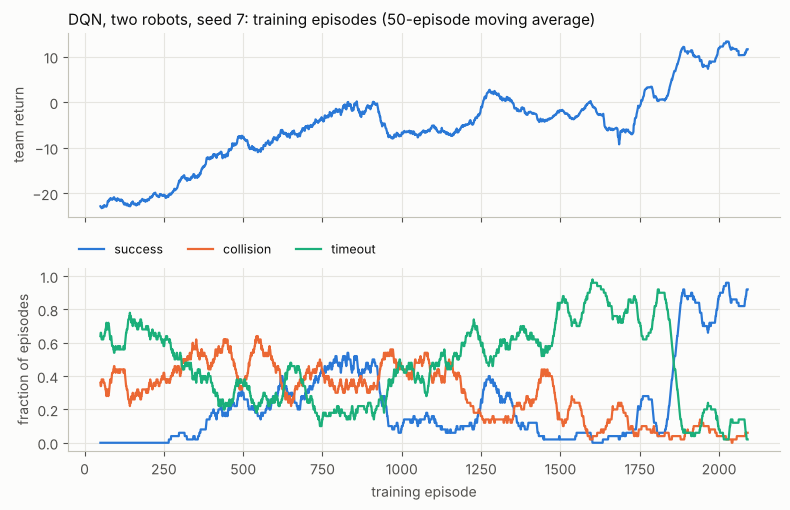

last 200 training episodes: success 0.83, collision 0.07, timeout 0.10


In [17]:
two_net, two_log = train_dqn(TwoRobotEnv(), encode_joint, 50, 25, total_steps=60_000)
print(f"{len(two_log['return'])} training episodes, {two_log['updates']} optimizer updates, "
      f"{two_log['syncs']} target-network syncs")

fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
x_ma = np.arange(WINDOW, len(two_log["return"]) + 1)
axes[0].plot(x_ma, moving_average(two_log["return"]), color=BLUE)
axes[0].set_ylabel("team return")
axes[0].set_title(f"DQN, two robots, seed {SEED}: training episodes ({WINDOW}-episode moving average)", loc="left")
for key, color in (("success", BLUE), ("collision", ORANGE), ("timeout", AQUA)):
    ma = moving_average(two_log[key])
    axes[1].plot(x_ma, ma, color=color, label=key)
axes[1].set_ylabel("fraction of episodes")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("training episode")
axes[1].legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

last = slice(-200, None)
print(f"last 200 training episodes: success {two_log['success'][last].mean():.2f}, "
      f"collision {two_log['collision'][last].mean():.2f}, timeout {two_log['timeout'][last].mean():.2f}")

### Greedy evaluation, seed 7

 t  A       B       joint action (A, B)   
 0  (2, 0)  (2, 4)                        
 1  (2, 1)  (2, 3)  (Right, Left)         
 2  (2, 2)  (1, 3)  (Right, Up)           
 3  (2, 3)  (1, 4)  (Right, Right)        
 4  (2, 4)  (1, 3)  (Right, Left)         
 5  (2, 4)  (2, 3)  (Down, Down)          
 6  (2, 4)  (2, 2)  (Left, Left)          
 7  (2, 4)  (2, 1)  (Up, Left)            
 8  (2, 4)  (2, 0)  (Right, Left)         

outcome success, 8 joint steps, 0 invalid moves, team return 14.2


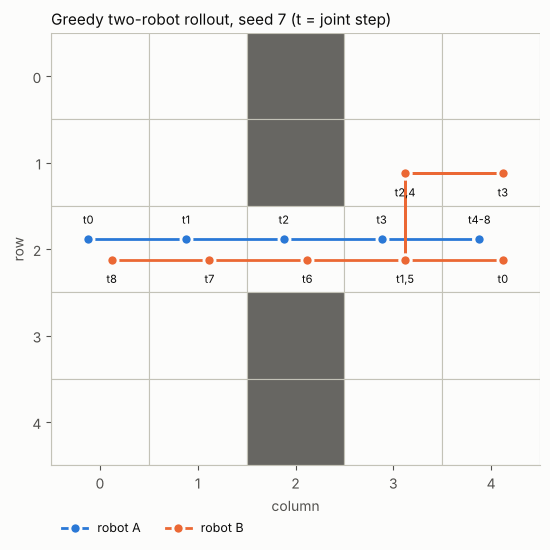

In [18]:
two_eval = greedy_rollout(TwoRobotEnv(), net_policy(two_net, encode_joint))
print(f"{'t':>2}  {'A':<8}{'B':<8}{'joint action (A, B)':<22}")
for t, (pA, pB) in enumerate(two_eval["path"]):
    act = "" if t == 0 else "(%s, %s)" % tuple(ACTIONS[x] for x in divmod(two_eval["actions"][t - 1], 5))
    print(f"{t:>2}  {str(pA):<8}{str(pB):<8}{act:<22}")
print(f"\noutcome {two_eval['outcome']}, {two_eval['steps']} joint steps, "
      f"{two_eval['invalid']} invalid moves, team return {two_eval['return']}")


def plot_two_robot(path, title):
    fig, ax = plt.subplots(figsize=(5.6, 5.6))
    ax.set_xlim(-0.5, COLS - 0.5)
    ax.set_ylim(ROWS - 0.5, -0.5)                   # rows increase downwards
    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xlabel("column")
    ax.set_ylabel("row")
    ax.grid(False)
    for r in range(ROWS):
        for c in range(COLS):
            ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor="#676662" if (r, c) in OBSTACLES
                                       else "#fcfcfb", edgecolor="#c3c2b7", linewidth=0.8))
    for i, (name, color, off, va) in enumerate((("A", BLUE, -0.12, "bottom"), ("B", ORANGE, 0.12, "top"))):
        cells = [p[i] for p in path]
        xs = [c + off for _, c in cells]
        ys = [r + off for r, _ in cells]
        ax.plot(xs, ys, color=color, linewidth=2, marker="o", markersize=8,
                markeredgecolor="#fcfcfb", markeredgewidth=2, label=f"robot {name}", zorder=3)
        times = {}
        for t, cell in enumerate(cells):
            times.setdefault(cell, []).append(t)
        for (r, c), ts in times.items():
            runs = [[ts[0], ts[0]]]
            for t in ts[1:]:
                if t == runs[-1][1] + 1:
                    runs[-1][1] = t
                else:
                    runs.append([t, t])
            text = "t" + ",".join(str(a) if a == b else f"{a}-{b}" for a, b in runs)
            ax.annotate(text, (c + off, r + off), xytext=(0, 9 if va == "bottom" else -9),
                        textcoords="offset points", ha="center", va=va, fontsize=8, color="#0b0b0b")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2, fontsize=9)
    ax.set_title(title, loc="left")
    fig.tight_layout()
    plt.show()

plot_two_robot(two_eval["path"], f"Greedy two-robot rollout, seed {SEED} (t = joint step)")

Seed 7 succeeds without a collision in 8 joint steps - one more than the 7-step
minimum - with no invalid moves.

**(a) Which robot entered the passage first?** A: it moves straight along row 2 and is in the
doorway $(2,2)$ at $t = 2$, delivered at $t = 4$. (The actions printed for A after $t = 4$ are
what the network asked for; a delivered robot ignores them and stays on its goal.)

**(b) Where did the other robot yield?** B steps into the doorway row only as far as $(2,3)$,
then moves up into the right room at $(1,3)$ at $t = 2$, out of A's lane. It drifts to $(1,4)$
at $t = 3$ and back to $(1,3)$ at $t = 4$ - that detour is the one wasted step compared with the
7-step optimum, since waiting at $(1,3)$ would have done - and then follows A's trail through the
doorway from $t = 5$, arriving at $(2,0)$ at $t = 8$.

**(c) Is avoiding collisions sufficient to count as success?** No. Success means both robots
delivered. A policy that never moves never collides, but it times out at 40 steps having
delivered nothing - which is exactly how the two runs below fail.

**(d) Joint-action output size for three robots.** $5^3 = 125$ outputs (and $3 \times 25 = 75$
one-hot inputs). The joint action space grows as $5^n$, which is why a single joint controller
does not scale to many robots.

### Other seeds - kept, not discarded

The same configuration with seeds 8 and 9:

In [19]:
other_seeds = {}
for seed in (8, 9):
    net_s, log_s = train_dqn(TwoRobotEnv(), encode_joint, 50, 25, total_steps=60_000, seed=seed)
    ev = greedy_rollout(TwoRobotEnv(), net_policy(net_s, encode_joint))
    other_seeds[seed] = (net_s, log_s, ev)
    print(f"seed {seed}: greedy outcome {ev['outcome']} after {ev['steps']} joint steps, {ev['invalid']} invalid moves; "
          f"last 200 training episodes: success {log_s['success'][-200:].mean():.2f}, "
          f"collision {log_s['collision'][-200:].mean():.2f}, timeout {log_s['timeout'][-200:].mean():.2f}")
    print("  joint steps 0-9 :", ev["path"][:10])
    print("  joint steps 37-40:", ev["path"][-4:])

seed 8: greedy outcome timeout after 40 joint steps, 0 invalid moves; last 200 training episodes: success 0.03, collision 0.17, timeout 0.80
  joint steps 0-9 : [((2, 0), (2, 4)), ((3, 0), (2, 3)), ((4, 0), (2, 2)), ((3, 0), (2, 1)), ((4, 0), (2, 1)), ((3, 0), (2, 0)), ((3, 1), (2, 0)), ((2, 1), (2, 0)), ((3, 1), (2, 0)), ((2, 1), (2, 0))]
  joint steps 37-40: [((2, 1), (2, 0)), ((3, 1), (2, 0)), ((2, 1), (2, 0)), ((3, 1), (2, 0))]


seed 9: greedy outcome timeout after 40 joint steps, 0 invalid moves; last 200 training episodes: success 0.03, collision 0.06, timeout 0.92
  joint steps 0-9 : [((2, 0), (2, 4)), ((3, 0), (2, 3)), ((2, 0), (2, 2)), ((3, 0), (2, 1)), ((3, 0), (1, 1)), ((3, 1), (1, 0)), ((2, 1), (1, 1)), ((2, 2), (0, 1)), ((2, 1), (1, 1)), ((2, 2), (0, 1))]
  joint steps 37-40: [((2, 2), (0, 1)), ((2, 1), (1, 1)), ((2, 2), (0, 1)), ((2, 1), (1, 1))]


Both fail, and in the same way: no collision, but a **timeout** - and their training logs agree,
with only 3% of the last 200 training episodes successful. Seed 8 delivers B
by $t = 5$, then A shuttles between $(2,1)$ and $(3,1)$ until the cutoff; seed 9 never delivers
either robot - A alternates between $(2,1)$ and $(2,2)$ while B alternates between $(1,1)$ and
$(0,1)$. A greedy policy that maps two joint states to each other loops forever, because nothing
in the state records how long it has been going. These are exactly the "robot that waits
forever avoids collisions while failing the delivery task" outcome the handout warns about, and
they show that the seed-7 success is not a reliable property of this configuration: 1 run out of
3 succeeded. A larger budget or more seeds would be the next step; the failures are reported
here as they are, and no planned route has been substituted for a learned one.

## Task 8 - Evaluating the agents

Greedy evaluation with learning disabled, from the default starts (one deterministic rollout
each):

In [20]:
rows = {
    "Q-table, one robot": (f"1,500 episodes, seed {SEED}", q_eval),
    "DQN, one robot": (f"12,000 steps, seed {SEED}", dqn_eval),
    "DQN, two robots": (f"60,000 steps, seed {SEED}", two_eval),
}
print(f"{'Measure':<28}" + "".join(f"{k:>26}" for k in rows))
print(f"{'Budget and seed':<28}" + "".join(f"{b:>26}" for b, _ in rows.values()))
print(f"{'Outcome':<28}" + "".join(f"{e['outcome']:>26}" for _, e in rows.values()))
print(f"{'Steps, if successful':<28}" + "".join(
    f"{e['steps'] if e['outcome'] == 'success' else '-':>26}" for _, e in rows.values()))
print(f"{'Invalid moves':<28}" + "".join(f"{e['invalid']:>26}" for _, e in rows.values()))

Measure                             Q-table, one robot            DQN, one robot           DQN, two robots
Budget and seed                 1,500 episodes, seed 7      12,000 steps, seed 7      60,000 steps, seed 7
Outcome                                        success                   success                   success
Steps, if successful                                 4                         4                         8
Invalid moves                                        0                         0                         0


### Additional starts, without retraining

One robot from $(0,0)$; two robots with A at $(0,0)$ and B at $(4,4)$. Map and goals unchanged.

In [21]:
alt_q = greedy_rollout(WarehouseEnv(), q_policy, start=(0, 0))
alt_dqn = greedy_rollout(WarehouseEnv(), net_policy(dqn, one_hot), start=(0, 0))
alt_two = greedy_rollout(TwoRobotEnv(), net_policy(two_net, encode_joint), start=((0, 0), (4, 4)))
for name, ev in (("Q-table from (0,0)", alt_q), ("DQN from (0,0)", alt_dqn),
                 ("two-robot DQN, A (0,0), B (4,4)", alt_two)):
    print(f"{name:<34} {ev['outcome']:<9} {ev['steps']:>2} steps, {ev['invalid']} invalid moves")
print("fewest possible joint steps from A (0,0), B (4,4):", min_joint_steps(((0, 0), (4, 4))))
print("\nQ-table route from (0,0):")
print(draw_path(alt_q["path"]))
print("\ntwo-robot route from A (0,0), B (4,4):")
for t, (pA, pB) in enumerate(alt_two["path"]):
    print(f"  t{t:<3} A {pA}  B {pB}")

Q-table from (0,0)                 success    6 steps, 0 invalid moves
DQN from (0,0)                     success    6 steps, 0 invalid moves
two-robot DQN, A (0,0), B (4,4)    success   11 steps, 2 invalid moves
fewest possible joint steps from A (0,0), B (4,4): 9

Q-table route from (0,0):
0 . # . .
1 . # . .
2 3 4 5 6
. . # . .
. . # . .

two-robot route from A (0,0), B (4,4):
  t0   A (0, 0)  B (4, 4)
  t1   A (0, 1)  B (4, 4)
  t2   A (0, 1)  B (3, 4)
  t3   A (1, 1)  B (3, 3)
  t4   A (2, 1)  B (3, 4)
  t5   A (2, 2)  B (2, 4)
  t6   A (2, 3)  B (3, 4)
  t7   A (2, 4)  B (3, 3)
  t8   A (2, 4)  B (2, 3)
  t9   A (2, 4)  B (2, 2)
  t10  A (2, 4)  B (2, 1)
  t11  A (2, 4)  B (2, 0)


All three policies still deliver from these starts. The single-robot policies
take 6 steps from $(0,0)$, which is the Manhattan distance to $G$ and so the shortest possible.
The two-robot policy takes 11 joint steps against a minimum of 9, and is less clean. It makes
2 invalid moves (-1 each): B tries to leave the grid from the corner $(4,4)$ at $t = 1$, and A,
at $(0,1)$, tries to move into the boundary or the obstacle at $(0,2)$ at $t = 2$. B then wanders
around the right room - $(3,4)$, $(3,3)$, back to $(3,4)$, briefly onto A's goal $(2,4)$ at
$t = 5$ and off it again - and only heads for the doorway once A has been delivered at $t = 7$.

This works because early training, with $\varepsilon$ close to 1, took the robots through most
of the grid, so states away from the default route also received useful value estimates - but
nothing guarantees it: a policy trained from one start is only checked on the states it happened
to visit. And each entry above is one deterministic greedy rollout; repeating it from the same
start would produce the identical trajectory, so it is one trial, not a success rate. The
one-robot and two-robot returns are also not comparable numbers: the two tasks have different
reward definitions (team reward with -10 collisions and +5 bonuses vs. +10 for a single
delivery).

## Reflection on the LLM's contribution

1. **Specified before requesting code:** the whole MDP (Task 1), the agent design (Task 2), and
   every parameter the handout fixes - map, coordinates, action codes, rewards, the
   termination/truncation distinction, $\alpha$, $\gamma$, $\varepsilon$ schedules, budgets,
   seeds, network sizes, replay and target-network settings, and the two-robot movement, collision
   and reward rules.
2. **Did the LLM change any rewards, stopping rules or algorithm details?** Not the specified
   ones - each is checked by a test or a printed counter above. It did fill in details the
   specification left open, which are worth stating: replay batches are sampled *without*
   replacement; the DQN breaks (practically impossible) exact ties between network outputs with
   `argmax`, not at random; the Q-table's $\varepsilon$ reaches 0.05 exactly at episode 1,200;
   and PyTorch runs on a single thread so that runs are repeatable.
3. **Errors the tests revealed:** none in the final code - the environment cases, the cutoff,
   the synthetic Q-update, the DQN loss batch and the two-robot collision cases all passed as
   written. They are still what makes the results interpretable: without them, the seed 8/9
   timeouts could not be told apart from an environment or target bug.
4. **Replay buffer and target network as requested?** Yes: `ReplayBuffer` holds 20,000
   transitions and serves uniform batches of 64; the target network is initialised from the
   online one and copied every 250 updates, and the printed counts (2,876 updates and 11 syncs for
   12,000 steps) match the schedule computed by hand.
5. **Functions that can be explained without the LLM:** every function a result depends on is
   explained where it is defined or used and pinned down by a test - `WarehouseEnv.step` and
   `TwoRobotEnv.step` (the rules), `q_update` and `dqn_loss` (the targets), `epsilon_greedy` and
   `linear_epsilon` (exploration), `train_q_learning` / `train_dqn` (the loops) and
   `greedy_rollout` (evaluation).
6. **What was changed, and the evidence:** nothing in the generated environment or update code
   needed changing after the tests. What *was* decided after seeing results was to keep and
   report the failed seeds 8 and 9 in Task 7 instead of presenting seed 7 alone - the evidence
   being their greedy rollouts, which loop until the cutoff.

> **Think about it.** What the program was *asked* to do is the specification above; what it
> *implements* is checked by the tests in Tasks 4, 6 and 7; what the experiments *demonstrate*
> is limited to the greedy rollouts and training logs shown - for the two-robot task, that one
> seed out of three learned a collision-free delivery within 60,000 steps.

## Optional - connecting the exercise to RLHF

1. **Feedback people would provide:** pairwise comparisons - shown two recorded two-robot
   trajectories, a person marks which one they prefer (e.g. the one that keeps more distance
   between the robots, or does not wait unnecessarily).
2. **What a learned reward model would predict:** a scalar score for a trajectory (or for each
   state-action step) trained so that preferred trajectories score higher than rejected ones -
   for example with a Bradley-Terry model, $P(\tau_1 \succ \tau_2) = \sigma(R(\tau_1) - R(\tau_2))$.
3. **How an RL agent would use it:** in place of (or added to) the hand-written team reward, so
   DQN's targets $r + \gamma \max_{a'} Q(s', a')$ would use the reward model's output as $r$.

**Does editing the hand-written collision penalty train a reward model?** No. Changing -10 to,
say, -20 is a designer choosing a number by hand; nothing is learned and no human comparison is
involved. In RLHF the reward function itself is *fitted to data* (people's preferences between
behaviours), which can capture things that are hard to write down as a formula, such as
"uncomfortably close" or "pointless waiting".

## Reproducibility

Seeds: 7 for everything (Q-learning, the random-policy baseline and both DQN runs), plus seeds 8
and 9 for the extra two-robot runs and seed 8 for the second no-exploration run. Budgets: 1,500
episodes (Q-table), 12,000 environment steps (DQN, one robot), 60,000 environment steps (DQN, two
robots). Everything runs on a CPU; PyTorch is limited to one thread. Exact numbers can differ on
other PyTorch versions or hardware.

In [22]:
import sys, matplotlib
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| PyTorch", torch.__version__,
      "| Matplotlib", matplotlib.__version__)

Python 3.13.17 | NumPy 2.5.4 | PyTorch 2.15.0+cpu | Matplotlib 3.11.2
